In [1]:
# -----------------------------------------------------------------------
# 0. Libraries and Reproducibility setup
# -----------------------------------------------------------------------

import sys
import os
import warnings
import numpy as np
import matplotlib
import scipy
import sklearn
from scipy import stats
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import (Matern, ConstantKernel, WhiteKernel)
from scipy.stats import norm
from scipy.optimize import minimize
from sklearn.model_selection import LeaveOneOut
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

SEED = 42
rng = np.random.default_rng(SEED)
SK_RANDOM_STATE = np.random.RandomState(SEED)  # sklearn wants a RandomState

print("=" * 100)
print("Software and Libraries used")
print("=" * 100)
print(f"  python      : {sys.version.split()[0]}")
print(f"  numpy       : {np.__version__}")
print(f"  scipy       : {scipy.__version__}")
print(f"  scikit-learn: {sklearn.__version__}")
print(f"  matplotlib  : {matplotlib.__version__}")
print(f"  SEED        : {SEED}")
print()

Software and Libraries used
  python      : 3.13.9
  numpy       : 2.3.5
  scipy       : 1.16.3
  scikit-learn: 1.9.0
  matplotlib  : 3.11.1
  SEED        : 42



In [2]:
# -----------------------------------------------------------------------
# 1. Data
# -----------------------------------------------------------------------
X = np.load('..\Function_5_Data\Week_9_Data/F5_Week_9_inputs.npy')
y = np.load('..\Function_5_Data\Week_9_Data/F5_Week_9_outputs.npy')
n, d = X.shape
bounds = np.array([[0.0, 1.0]] * d)
dim_names = [f"x{i+1}" for i in range(d)]


In [3]:
# -----------------------------------------------------------------------
# Re-run the exploratory diagnostics with the 2 new points included
# -----------------------------------------------------------------------
print("=" * 100)
print("Updated exploratory summary (n=%d)" % n)
print("=" * 100)
print(f"y min={y.min():.4g}, max={y.max():.4g}, mean={y.mean():.4g}, "
      f"std={y.std():.4g}")
print(f"y ratio max/min = {y.max()/y.min():.1f} -> spans "
      f"{np.log10(y.max()/y.min()):.1f} orders of magnitude "
      f"(was 4.7 orders with 26 points - the 2 new high values *widened* "
      f"the spread, they didn't narrow it)")
print(f"skewness of raw y = {stats.skew(y):.2f} (was 3.26 before - still "
      f"heavily right-skewed, marginally more so)")
bc_y, bc_lambda = stats.boxcox(y)
print(f"Box-Cox fitted lambda = {bc_lambda:.3f} (was 0.089 before - "
      f"still close to 0, i.e. log is still close to the data-optimal "
      f"power transform)")


Updated exploratory summary (n=28)
y min=0.1129, max=8449, mean=1030, std=2008
y ratio max/min = 74814.2 -> spans 4.9 orders of magnitude (was 4.7 orders with 26 points - the 2 new high values *widened* the spread, they didn't narrow it)
skewness of raw y = 2.49 (was 3.26 before - still heavily right-skewed, marginally more so)
Box-Cox fitted lambda = 0.068 (was 0.089 before - still close to 0, i.e. log is still close to the data-optimal power transform)


In [4]:
# -----------------------------------------------------------------------
# Build the two competing surrogates:
#   A) log(y) + GP
#   B) raw y, standardised (normalize_y=True on raw y) 
# -----------------------------------------------------------------------

def make_gp(ard: bool, n_restarts=20):
    ls = np.full(d, 1.0) if ard else 1.0
    kernel = (
        ConstantKernel(1.0, (1e-3, 1e3))
        * Matern(length_scale=ls, length_scale_bounds=(1e-2, 1e2), nu=2.5)
        + WhiteKernel(noise_level=1e-4, noise_level_bounds=(1e-8, 1e-1))
    )
    return GaussianProcessRegressor(
        kernel=kernel,
        normalize_y=True,       # standardises whatever target is passed in
        alpha=1e-10,
        n_restarts_optimizer=n_restarts,
        random_state=SK_RANDOM_STATE,
    )


def loo_nlpd(target, ard, n_restarts=5):
    """Mean negative log predictive density under leave-one-out CV."""
    loo = LeaveOneOut()
    nlpds = []
    for train_idx, test_idx in loo.split(X):
        gp_i = make_gp(ard=ard, n_restarts=n_restarts)
        gp_i.fit(X[train_idx], target[train_idx])
        mu, sigma = gp_i.predict(X[test_idx], return_std=True)
        sigma = max(sigma[0], 1e-6)
        nlpd = 0.5 * np.log(2 * np.pi * sigma ** 2) + \
            0.5 * ((target[test_idx][0] - mu[0]) ** 2) / (sigma ** 2)
        nlpds.append(nlpd)
    return np.mean(nlpds)


def loo_nlpd_original_scale(target_transform, inverse_transform, ard, n_restarts=5):
    """LOO negative log predictive density, but evaluated back on the
    ORIGINAL y scale (via a Gaussian approximation / Monte Carlo for the
    log case) so log-space and raw-space models are directly comparable
    on a common footing (not just in their own transformed units)."""
    loo = LeaveOneOut()
    nlpds = []
    rng_local = np.random.default_rng(SEED)
    for train_idx, test_idx in loo.split(X):
        gp_i = make_gp(ard=ard, n_restarts=n_restarts)
        gp_i.fit(X[train_idx], target_transform(y[train_idx]))
        mu, sigma = gp_i.predict(X[test_idx], return_std=True)
        sigma = max(sigma[0], 1e-6)
        # Monte-Carlo the predictive density on the y-scale by sampling
        # from the transformed-space Gaussian and inverse-transforming.
        samples = rng_local.normal(mu[0], sigma, size=20000)
        y_samples = inverse_transform(samples)
        y_true = y[test_idx][0]
        # KDE-free density estimate: Gaussian kernel density around y_true
        bw = np.std(y_samples) * (len(y_samples) ** (-1 / 5)) + 1e-6
        dens = np.mean(norm.pdf((y_true - y_samples) / bw)) / bw
        dens = max(dens, 1e-300)
        nlpds.append(-np.log(dens))
    return np.mean(nlpds)


print("\nRunning leave-one-out comparisons across %d points "
      "(this refits %d GPs per configuration)..." % (n, n))

configs = {
    "log(y), isotropic":  dict(target=np.log(y), ard=False),
    "log(y), ARD":        dict(target=np.log(y), ard=True),
    "raw y (standardised), isotropic": dict(target=y, ard=False),
    "raw y (standardised), ARD":       dict(target=y, ard=True),
}

results = {}
for name, cfg in configs.items():
    results[name] = loo_nlpd(cfg["target"], cfg["ard"])

print("\nLOO mean negative log predictive density, IN EACH MODEL'S OWN "
      "TRANSFORMED UNITS (log-y units for the two log rows, raw-y units "
      "for the two raw rows - these two groups are NOT directly comparable "
      "to each other on this line, see the common-scale comparison below):")
for name, val in results.items():
    print(f"  {name:38s}: {val:8.3f}")

# Common-scale comparison: back-transform everything onto the y scale so
# log(y) vs raw-y models can be compared on equal footing.
print("\nCommon-scale comparison (both models judged on their ability to "
      "predict the ACTUAL y value of a held-out point, in y units):")
common = {
    "log(y), isotropic": loo_nlpd_original_scale(
        np.log, np.exp, ard=False),
    "raw y (standardised), isotropic": loo_nlpd_original_scale(
        lambda v: v, lambda v: v, ard=False),
}
for name, val in common.items():
    print(f"  {name:38s}: {val:8.3f}  (lower = better)")

better_name = min(common, key=common.get)
print(f"\n-> On a common y-scale footing, '{better_name}' is the better "
      f"predictive model of the two.")



Running leave-one-out comparisons across 28 points (this refits 28 GPs per configuration)...

LOO mean negative log predictive density, IN EACH MODEL'S OWN TRANSFORMED UNITS (log-y units for the two log rows, raw-y units for the two raw rows - these two groups are NOT directly comparable to each other on this line, see the common-scale comparison below):
  log(y), isotropic                     :    2.079
  log(y), ARD                           :    3.099
  raw y (standardised), isotropic       :    7.292
  raw y (standardised), ARD             :   76.258

Common-scale comparison (both models judged on their ability to predict the ACTUAL y value of a held-out point, in y units):
  log(y), isotropic                     :    6.993  (lower = better)
  raw y (standardised), isotropic       :    7.282  (lower = better)

-> On a common y-scale footing, 'log(y), isotropic' is the better predictive model of the two.


In [5]:
# -----------------------------------------------------------------------
# ARD vs isotropic, re-checked
# -----------------------------------------------------------------------
print("=" * 100)
print("ARD vs isotropic, re-checked")
print("=" * 100)
loo_log_iso = results["log(y), isotropic"]
loo_log_ard = results["log(y), ARD"]
print(f"log(y) isotropic LOO NLPD = {loo_log_iso:.3f}")
print(f"log(y) ARD       LOO NLPD = {loo_log_ard:.3f}")
chosen_ard = loo_log_ard < loo_log_iso
note = ("a reversal from the n=26 result - worth re-checking again after "
        "the next few rounds") if chosen_ard else "consistent with the n=26 result"
print(f"-> {'ARD' if chosen_ard else 'isotropic'} still wins with the 2 "
      f"extra points ({note}).")

ARD vs isotropic, re-checked
log(y) isotropic LOO NLPD = 2.079
log(y) ARD       LOO NLPD = 3.099
-> isotropic still wins with the 2 extra points (consistent with the n=26 result).


In [6]:
# -----------------------------------------------------------------------
# Fit the recommended surrogate on log(y), propose next point
# -----------------------------------------------------------------------
gp = make_gp(ard=chosen_ard, n_restarts=30)
target = np.log(y)
gp.fit(X, target)
f_best = target.max()
print(f"\nFinal recommended surrogate: log(y), "
      f"{'ARD' if chosen_ard else 'isotropic'} Matern-5/2")
print(f"Kernel: {gp.kernel_}")


xi = 0.002  # was 0.01 with a longer horizon; smaller now budget is tight

def expected_improvement(Xcand, gp, f_best, xi):
    Xcand = np.atleast_2d(Xcand)
    mu, sigma = gp.predict(Xcand, return_std=True)
    sigma = np.maximum(sigma, 1e-9)
    imp = mu - f_best - xi
    Z = imp / sigma
    ei = imp * norm.cdf(Z) + sigma * norm.pdf(Z)
    ei[sigma < 1e-9] = 0.0
    return ei


def neg_ei(x, gp, f_best, xi):
    return -expected_improvement(x.reshape(1, -1), gp, f_best, xi)[0]


N_RESTARTS_ACQ = 300
starts = rng.uniform(bounds[:, 0], bounds[:, 1], size=(N_RESTARTS_ACQ, d))
best_x, best_val = None, np.inf
all_optima = []
for x0 in starts:
    res = minimize(neg_ei, x0, args=(gp, f_best, xi), bounds=bounds, method="L-BFGS-B")
    all_optima.append((res.x, -res.fun))
    if res.fun < best_val:
        best_val = res.fun
        best_x = res.x

incumbent_idx = np.argmax(y)
print(f"\nCurrent incumbent: x*={X[incumbent_idx].round(6)}, y*={y.max():.2f}")
print(f"Proposed round-4 query point (argmax EI, xi={xi}): {best_x.round(6)}")
mu_new, sigma_new = gp.predict(best_x.reshape(1, -1), return_std=True)
print(f"GP posterior at proposed point (log-y space): "
      f"mean={mu_new[0]:.3f}, std={sigma_new[0]:.3f}")
print(f"-> back-transformed median prediction for y: {np.exp(mu_new[0]):.1f} "
      f"(90% CI: [{np.exp(mu_new[0]-1.645*sigma_new[0]):.1f}, "
      f"{np.exp(mu_new[0]+1.645*sigma_new[0]):.1f}])")



Final recommended surrogate: log(y), isotropic Matern-5/2
Kernel: 1.13**2 * Matern(length_scale=0.477, nu=2.5) + WhiteKernel(noise_level=1e-08)

Current incumbent: x*=[0.988753 1.       1.       1.      ], y*=8449.50
Proposed round-4 query point (argmax EI, xi=0.002): [1.       1.       1.       0.729546]
GP posterior at proposed point (log-y space): mean=8.368, std=1.477
-> back-transformed median prediction for y: 4305.3 (90% CI: [379.0, 48908.0])


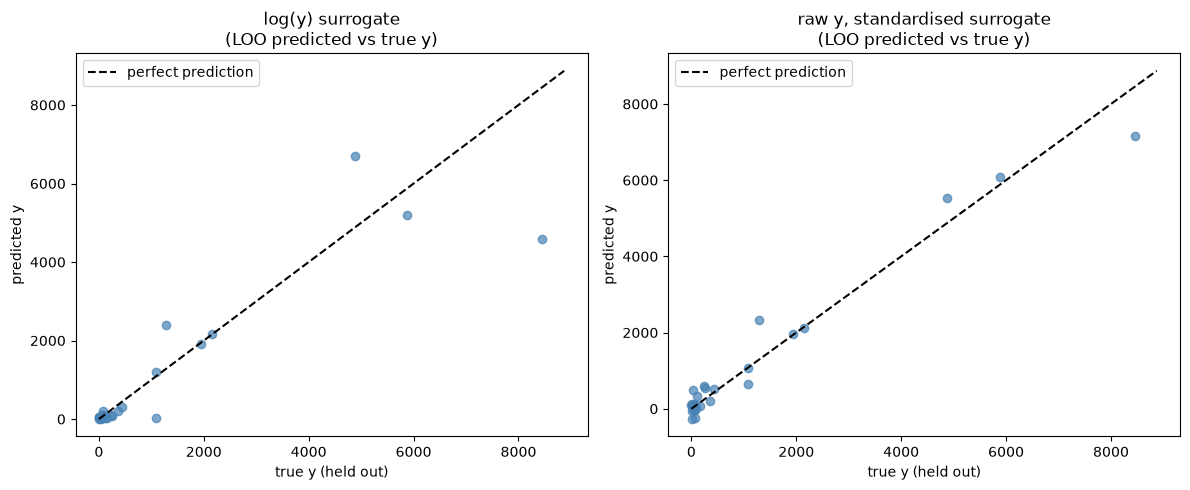

In [7]:
# -----------------------------------------------------------------------
# Figure: LOO fit comparison, log(y) vs raw-y models, common y-scale
# -----------------------------------------------------------------------
def loo_predictions_y_scale(target_transform, inverse_transform, ard, n_restarts=5):
    loo = LeaveOneOut()
    preds, trues = [], []
    for train_idx, test_idx in loo.split(X):
        gp_i = make_gp(ard=ard, n_restarts=n_restarts)
        gp_i.fit(X[train_idx], target_transform(y[train_idx]))
        mu, sigma = gp_i.predict(X[test_idx], return_std=True)
        preds.append(inverse_transform(np.array([mu[0]]))[0])
        trues.append(y[test_idx][0])
    return np.array(preds), np.array(trues)


pred_log, true_log = loo_predictions_y_scale(np.log, np.exp, ard=False)
pred_raw, true_raw = loo_predictions_y_scale(lambda v: v, lambda v: v, ard=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, preds, trues, title in [
    (axes[0], pred_log, true_log, "log(y) surrogate\n(LOO predicted vs true y)"),
    (axes[1], pred_raw, true_raw, "raw y, standardised surrogate\n(LOO predicted vs true y)"),
]:
    ax.scatter(trues, preds, c="steelblue", alpha=0.7)
    lims = [0, max(trues.max(), preds.max()) * 1.05]
    ax.plot(lims, lims, "k--", label="perfect prediction")
    ax.set_xlabel("true y (held out)")
    ax.set_ylabel("predicted y")
    ax.set_title(title)
    ax.legend()
plt.tight_layout()